<a href="https://colab.research.google.com/github/nasy-sr/indobert-ruangguru-sentiment/blob/main/01_eda_preprocessing_bigram.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

drive.mount('/content/drive')

Mounted at /content/drive


Memuat dan Menggabungkan Dataset

In [ ]:
path_file1 = '/content/drive/MyDrive/Seminar_Nasional_2026/ruangguru.csv'
path_file2 = '/content/drive/MyDrive/Seminar_Nasional_2026/Ruangguru.csv'

df1 = pd.read_csv(path_file1)[['content', 'score']]
df2 = pd.read_csv(path_file2)[['content', 'score']]

df_master = pd.concat([df1, df2], ignore_index=True)

df_master = df_master.dropna(subset=['content', 'score'])
df_master = df_master.drop_duplicates(subset=['content'])
df_master = df_master.rename(columns={'content': 'review', 'score': 'rating'})

Text Preprocessing dan Pelabelan Sentimen

In [ ]:
def clean_text_for_bert(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_master['clean_review'] = df_master['review'].apply(clean_text_for_bert)
df_master = df_master[df_master['clean_review'] != '']

def map_sentiment(rating):
    if rating <= 2: return 'Negatif'
    elif rating == 3: return 'Netral'
    else: return 'Positif'

df_master['sentiment'] = df_master['rating'].apply(map_sentiment)
df_master['review_length'] = df_master['clean_review'].apply(lambda x: len(x.split()))

Visualisasi Distribusi Sentimen

/tmp/ipykernel_1058/2230963454.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_master, x='sentiment', order=['Positif', 'Netral', 'Negatif'], palette=['#2ca02c', '#1f77b4', '#d62728'])


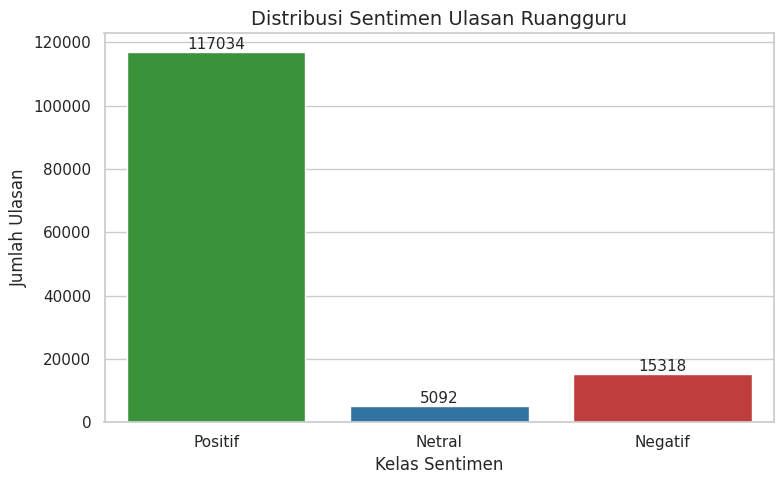

In [ ]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_master, x='sentiment', order=['Positif', 'Netral', 'Negatif'], palette=['#2ca02c', '#1f77b4', '#d62728'])
plt.title('Distribusi Sentimen Ulasan Ruangguru', fontsize=14)
plt.xlabel('Kelas Sentimen')
plt.ylabel('Jumlah Ulasan')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=11)
plt.tight_layout()
plt.show()

Visualisasi Distribusi Panjang Ulasan

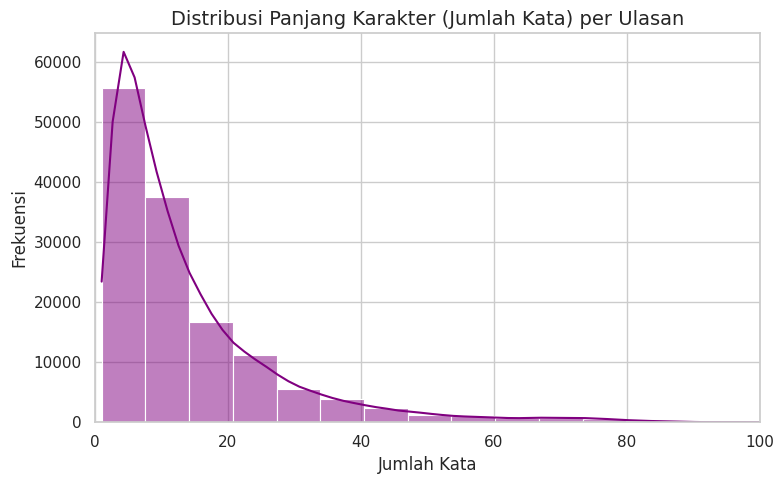

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df_master['review_length'], bins=50, kde=True, color='purple')
plt.title('Distribusi Panjang Karakter (Jumlah Kata) per Ulasan', fontsize=14)
plt.xlabel('Jumlah Kata')
plt.ylabel('Frekuensi')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

WordCloud Ulasan Positif

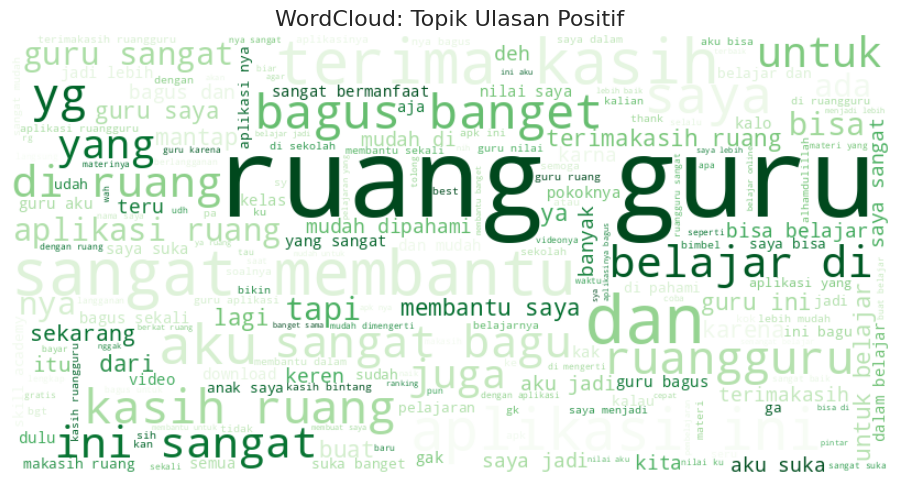

In [ ]:
positive_text = ' '.join(df_master[df_master['sentiment'] == 'Positif']['clean_review'].sample(n=min(10000, len(df_master[df_master['sentiment'] == 'Positif'])), random_state=42))
wordcloud_pos = WordCloud(width=800, height=400, background_color='white', colormap='Greens').generate(positive_text)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_pos, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud: Topik Ulasan Positif', fontsize=16)
plt.tight_layout()
plt.show()

WordCloud Ulasan Negatif

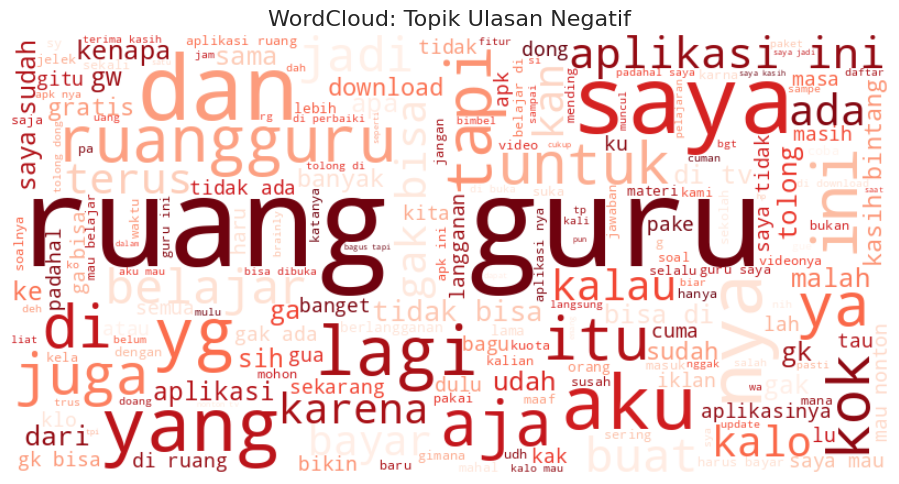

In [ ]:
negative_text = ' '.join(df_master[df_master['sentiment'] == 'Negatif']['clean_review'].sample(n=min(10000, len(df_master[df_master['sentiment'] == 'Negatif'])), random_state=42))
wordcloud_neg = WordCloud(width=800, height=400, background_color='white', colormap='Reds').generate(negative_text)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_neg, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud: Topik Ulasan Negatif', fontsize=16)
plt.tight_layout()
plt.show()

Setup Fungsi Ekstraksi N-Gram

In [ ]:
def get_top_ngram(corpus, n=None, ngram_range=(2,2)):
    vec = CountVectorizer(ngram_range=ngram_range).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key = lambda x: x[1], reverse=True)
    return words_freq[:n]

Visualisasi Top 10 Bigram (Keluhan Utama)

/tmp/ipykernel_1058/854639165.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=y_neg, y=x_neg, palette='Reds_r')


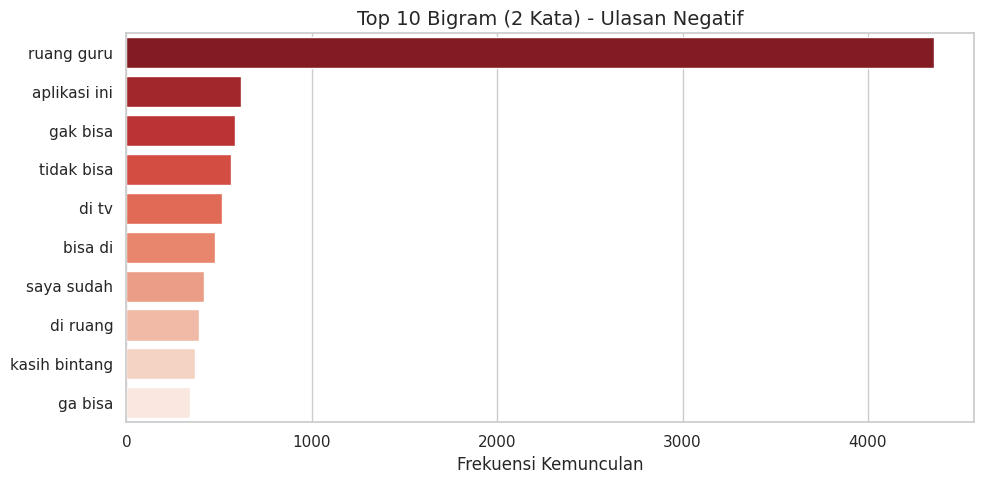

In [ ]:
neg_reviews = df_master[df_master['sentiment'] == 'Negatif']['clean_review']
top_neg_bigrams = get_top_ngram(neg_reviews, n=10, ngram_range=(2,2))

x_neg, y_neg = map(list, zip(*top_neg_bigrams))
plt.figure(figsize=(10, 5))
sns.barplot(x=y_neg, y=x_neg, palette='Reds_r')
plt.title('Top 10 Bigram (2 Kata) - Ulasan Negatif', fontsize=14)
plt.xlabel('Frekuensi Kemunculan')
plt.tight_layout()
plt.show()

Visualisasi Top 10 Bigram (Apresiasi Utama)

/tmp/ipykernel_1058/701226782.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=y_pos, y=x_pos, palette='Greens_r')


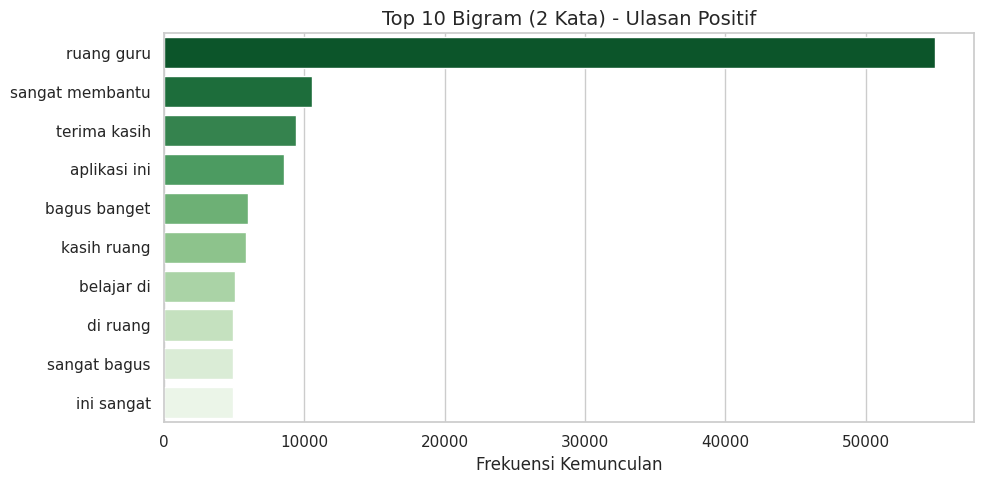

In [ ]:
pos_reviews = df_master[df_master['sentiment'] == 'Positif']['clean_review']
top_pos_bigrams = get_top_ngram(pos_reviews, n=10, ngram_range=(2,2))

x_pos, y_pos = map(list, zip(*top_pos_bigrams))
plt.figure(figsize=(10, 5))
sns.barplot(x=y_pos, y=x_pos, palette='Greens_r')
plt.title('Top 10 Bigram (2 Kata) - Ulasan Positif', fontsize=14)
plt.xlabel('Frekuensi Kemunculan')
plt.tight_layout()
plt.show()

Menyimpan Data Bersih

In [ ]:
csv_filename = '/content/drive/MyDrive/Seminar_Nasional_2026/Ruangguru_cleaned_for_indobert.csv'
df_master.to_csv(csv_filename, index=False)

Persiapan Lingkungan Cloud

In [ ]:
!pip install transformers[torch] datasets scikit-learn

Persiapan Data dan Stratified Sampling

In [ ]:
from google.colab import drive
import pandas as pd
from sklearn.model_selection import train_test_split

drive.mount('/content/drive')

df_classification = pd.read_csv('/content/drive/MyDrive/Seminar_Nasional_2026/Ruangguru_cleaned_for_indobert.csv')
df_classification = df_classification.dropna(subset=['clean_review']).copy()

label_map = {'Negatif': 0, 'Netral': 1, 'Positif': 2}
df_classification['label'] = df_classification['sentiment'].map(label_map)

# Stratified Sub-Sampling (Ambil 15.000 data)
max_samples = 15000
_, df_sampled = train_test_split(df_classification, test_size=max_samples/len(df_classification), stratify=df_classification['label'], random_state=42)
df_sampled = df_sampled.reset_index(drop=True)

print(f"Data berhasil dimuat! Total sampel untuk training: {len(df_sampled)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data berhasil dimuat! Total sampel untuk training: 15000


Konfigurasi IndoBERT dan F1-Score

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from transformers import AutoTokenizer

model_name = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)

    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='macro')
    acc = accuracy_score(labels, preds)

    return {
        'accuracy': acc,
        'f1_score': f1,
        'precision': precision,
        'recall': recall
    }

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Eksekusi 10-Fold Cross Validation

In [ ]:
from sklearn.model_selection import StratifiedKFold
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
import torch
import gc
import numpy as np

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
fold_f1_scores = []
fold_accuracies = []

hf_dataset = Dataset.from_pandas(df_sampled[['clean_review', 'label']])

def tokenize_function(examples):
    return tokenizer(examples["clean_review"], padding="max_length", truncation=True, max_length=64)

tokenized_datasets = hf_dataset.map(tokenize_function, batched=True)

training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    weight_decay=0.01,
    logging_dir='./logs',
    logging_steps=100,
    save_strategy="no",
    eval_strategy="epoch"
)

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(df_sampled)), df_sampled['label'])):
    print(f"\n--- Memulai Fold {fold + 1} ---")

    train_dataset = tokenized_datasets.select(train_idx)
    eval_dataset = tokenized_datasets.select(val_idx)

    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        compute_metrics=compute_metrics,
    )

    trainer.train()
    eval_results = trainer.evaluate()

    f1 = eval_results['eval_f1_score']
    acc = eval_results['eval_accuracy']
    fold_f1_scores.append(f1)
    fold_accuracies.append(acc)

    print(f"F1-Score Fold {fold + 1}: {f1:.4f}")

    del model, trainer
    torch.cuda.empty_cache()
    gc.collect()

print("\n==============================")
print(f"Rata-rata F1-Score: {np.mean(fold_f1_scores):.4f}")
print(f"Rata-rata Akurasi: {np.mean(fold_accuracies):.4f}")

Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

[transformers] `logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.



--- Memulai Fold 1 ---


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (63 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,F1 Score,Precision,Recall
1,0.312883,0.316257,0.890000,0.520274,0.521551,0.520236
2,0.227335,0.334951,0.896000,0.554645,0.594451,0.544378


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Training Loss,Validation Loss,Epoch,Accuracy,F1 Score,Precision,Recall
0.227335,0.334951,2,0.896000,0.554645,0.594451,0.544378


F1-Score Fold 10: 0.5546

Rata-rata F1-Score: 0.5698
Rata-rata Akurasi: 0.8967
